In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install required libraries
!pip install seaborn scikit-learn --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import skew
from pandas.plotting import parallel_coordinates

# Sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Models
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier


# Plot settings
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Colab/Georgia_census_data.csv')

# Basic info
print(df.shape)
df.head()

(2796, 20)


,NAME,B01003_001E,B19013_001E,B17001_002E,B01002_001E,B15003_022E,B15003_023E,B15003_024E,B15003_025E,B23025_005E,B23025_003E,B25077_001E,B25064_001E,B25001_001E,B02001_001E,B02001_002E,state,county,tract,GEOID
0,Census Tract 9501; Appling County; Georgia,3219,50222,631,36.2,125,84,14,0,22,1418,66500,-666666666,1574,3219,2557,13,1,950100,13001950100
1,Census Tract 9502.01; Appling County; Georgia,2246,57653,481,44.0,102,175,6,24,13,1063,151600,838,1049,2246,1704,13,1,950201,13001950201
2,Census Tract 9502.02; Appling County; Georgia,2152,29899,481,43.1,95,9,14,0,55,634,-666666666,734,986,2152,886,13,1,950202,13001950202
3,Census Tract 9503.01; Appling County; Georgia,3264,45486,796,39.9,124,145,51,0,42,1060,77400,855,1434,3264,2064,13,1,950301,13001950301
4,Census Tract 9503.02; Appling County; Georgia,2144,38673,637,41.9,193,0,3,9,97,1027,58700,756,1200,2144,1560,13,1,950302,13001950302


In [ ]:
#Renaming variables
rename_dict = {"B01003_001E": "Totalpop",
                "B19013_001E":"Median_Income",
                "B17001_002E": "Poverty_Count",
               "B01002_001E": "Age",
               "B15003_022E":"bachelors",
               "B15003_023E":"masters",
               "B15003_024E":"prof_degree",
               "B15003_025E":"doctorate",
               "B23025_005E": "unemployment",
               "B23025_003E":"total_labor",
               "B25077_001E":"home_value",
               "B25064_001E": "rent",
               "B02001_001E":"total_race"}


df = df.rename(columns=rename_dict)


In [ ]:
target = "NAME"

features = [
    "Totalpop", "Median_Income", "Poverty_Count", "Age",
    "bachelors", "masters", "prof_degree", "doctorate",
    "unemployment", "total_labor", "home_value", "rent", "total_race"
]

df = df[features + [target]].dropna()


print(f"New shape: {df.shape}")
df.head()

New shape: (2796, 14)


,Totalpop,Median_Income,Poverty_Count,Age,bachelors,masters,prof_degree,doctorate,unemployment,total_labor,home_value,rent,total_race,NAME
0,3219,50222,631,36.2,125,84,14,0,22,1418,66500,-666666666,3219,Census Tract 9501; Appling County; Georgia
1,2246,57653,481,44.0,102,175,6,24,13,1063,151600,838,2246,Census Tract 9502.01; Appling County; Georgia
2,2152,29899,481,43.1,95,9,14,0,55,634,-666666666,734,2152,Census Tract 9502.02; Appling County; Georgia
3,3264,45486,796,39.9,124,145,51,0,42,1060,77400,855,3264,Census Tract 9503.01; Appling County; Georgia
4,2144,38673,637,41.9,193,0,3,9,97,1027,58700,756,2144,Census Tract 9503.02; Appling County; Georgia


CLEANING DATA

In [ ]:
#Summary statistics

summary = df[features].describe()
print(summary)

           Totalpop  Median_Income  Poverty_Count           Age    bachelors  \
count   2796.000000   2.796000e+03    2796.000000  2.796000e+03  2796.000000   
mean    3912.878040  -7.548356e+06     511.449213 -2.861192e+06   554.343348   
std     1640.379873   7.093280e+07     413.639859  4.358876e+07   424.620904   
min        0.000000  -6.666667e+08       0.000000 -6.666667e+08     0.000000   
25%     2745.750000   5.464800e+04     211.000000  3.410000e+01   239.000000   
50%     3760.000000   7.351300e+04     414.500000  3.840000e+01   445.000000   
75%     4861.250000   1.001090e+05     692.000000  4.310000e+01   776.500000   
max    13456.000000   2.500010e+05    3346.000000  7.390000e+01  3135.000000   

           masters  prof_degree    doctorate  unemployment  total_labor  \
count  2796.000000  2796.000000  2796.000000   2796.000000  2796.000000   
mean    260.473534    62.810086    42.227468    100.931330  1965.687053   
std     230.793503    80.837052    59.319285     91.90

In [ ]:
#Missing values check

missing = pd.DataFrame({
    'Missing (NaN)': df[features].isnull().sum(),
    'Zero Values': (df[features] == 0).sum(),
    'Data Type': df[features].dtypes
})

print(missing)

               Missing (NaN)  Zero Values Data Type
Totalpop                   0           12     int64
Median_Income              0            0     int64
Poverty_Count              0           25     int64
Age                        0            0   float64
bachelors                  0           15     int64
masters                    0           33     int64
prof_degree                0          465     int64
doctorate                  0          702     int64
unemployment               0          110     int64
total_labor                0           13     int64
home_value                 0            0     int64
rent                       0            0     int64
total_race                 0           12     int64


In [ ]:
#Getting rid of places where zero is literally impossible

zero_cols = ['Totalpop', 'Median_Income', 'total_labor', 'total_race']

df = df[(df[zero_cols] > 0).all(axis=1)]



In [ ]:
#Outliers check

Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

extreme_low = Q1 - 3 * IQR
extreme_high = Q3 + 3 * IQR

outlier_report = ((df[features] < extreme_low) | (df[features] > extreme_high)).sum()

print("Extreme Outlier Count")
print(outlier_report)

Extreme Outlier Count
Totalpop           6
Median_Income     20
Poverty_Count     15
Age                1
bachelors          5
masters            9
prof_degree       55
doctorate         43
unemployment      26
total_labor        4
home_value        83
rent             164
total_race         6
dtype: int64


In [ ]:
df = df[df['Median_Income'] > 0]
df = df[df['home_value'] > 0]
df = df[df['rent'] > 0]
#After looking at the histograms, I went back and got rid of the extreme outliers for Median Income, home value, and rent
# (they were in the -666666 range most likely coded as missing)

In [ ]:
#Missing values check Again

missing = pd.DataFrame({
    'Missing (NaN)': df[features].isnull().sum(),
    'Zero Values': (df[features] == 0).sum(),
    'Data Type': df[features].dtypes
})

print(missing)

#There's still some zeroes, but in theory they're possible??

               Missing (NaN)  Zero Values Data Type
Totalpop                   0            0     int64
Median_Income              0            0     int64
Poverty_Count              0            8     int64
Age                        0            0   float64
bachelors                  0            2     int64
masters                    0           17     int64
prof_degree                0          400     int64
doctorate                  0          610     int64
unemployment               0           76     int64
total_labor                0            0     int64
home_value                 0            0     int64
rent                       0            0     int64
total_race                 0            0     int64


UNIVARIATE ANALYSIS

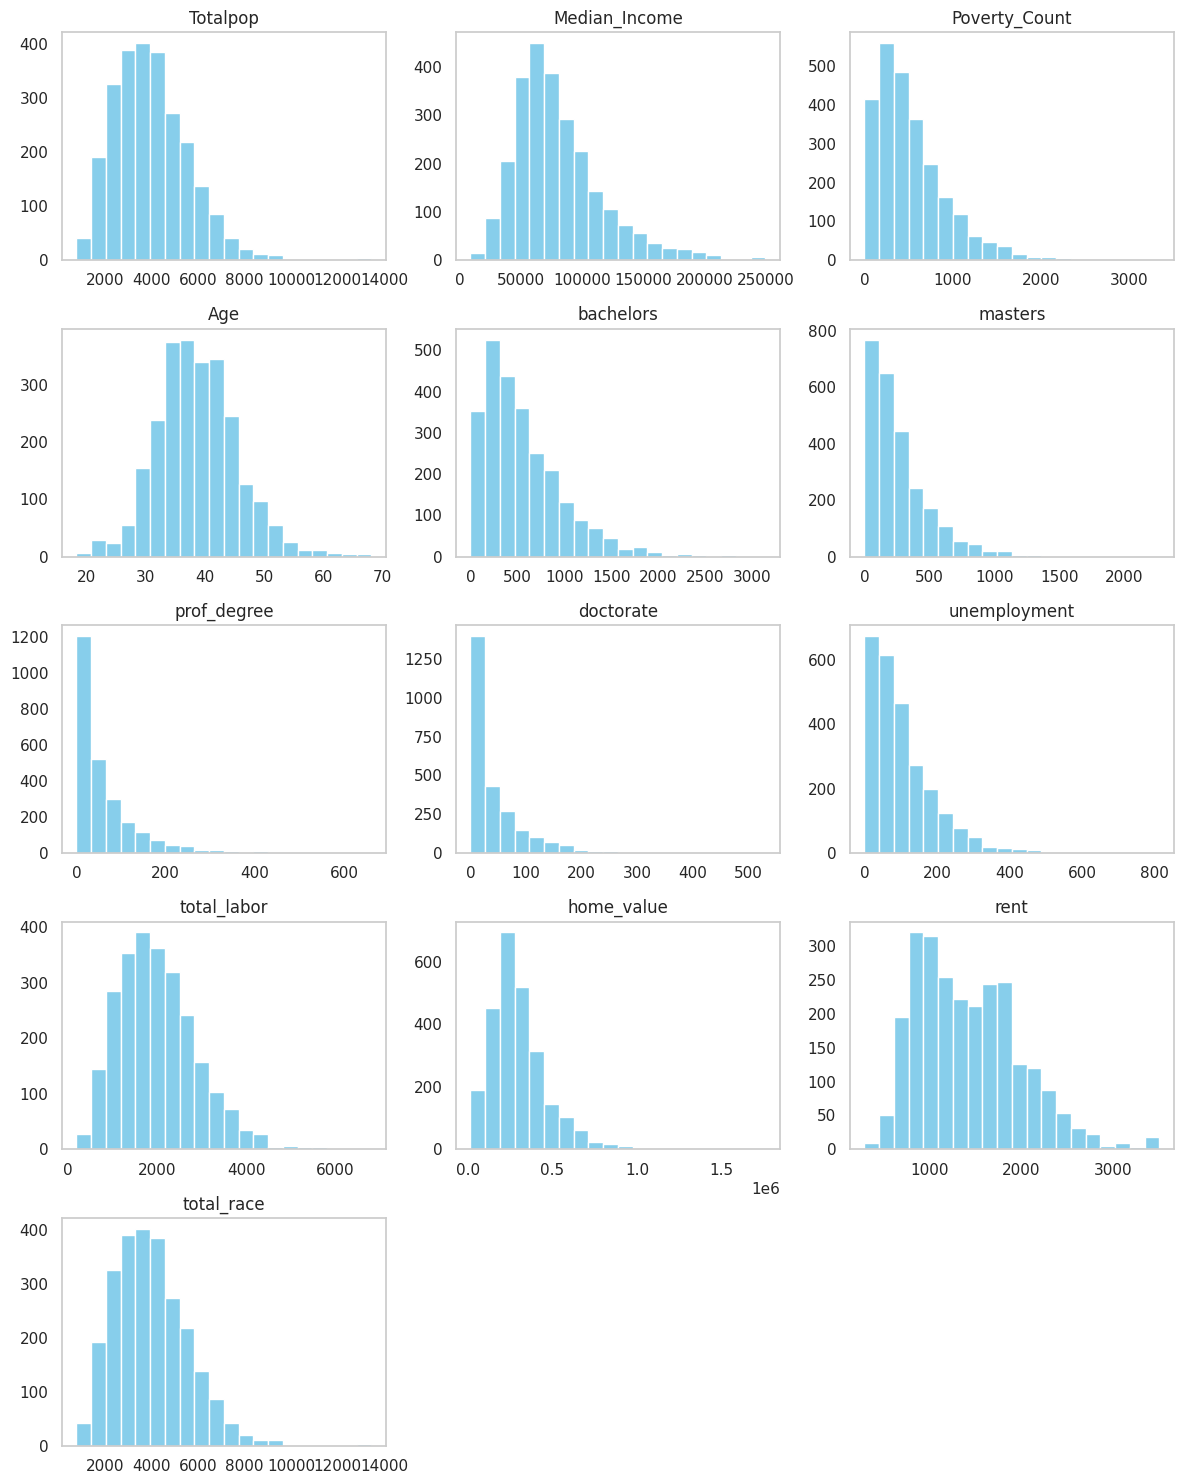

In [ ]:
#Did get it to work without need sample, so removed that line from here

#HISTOGRAM
df.hist(bins=20,
             figsize=(12, 15),
             layout=(5, 3),
             color='skyblue',
             edgecolor='white',
             grid=False)

plt.tight_layout()
plt.show()

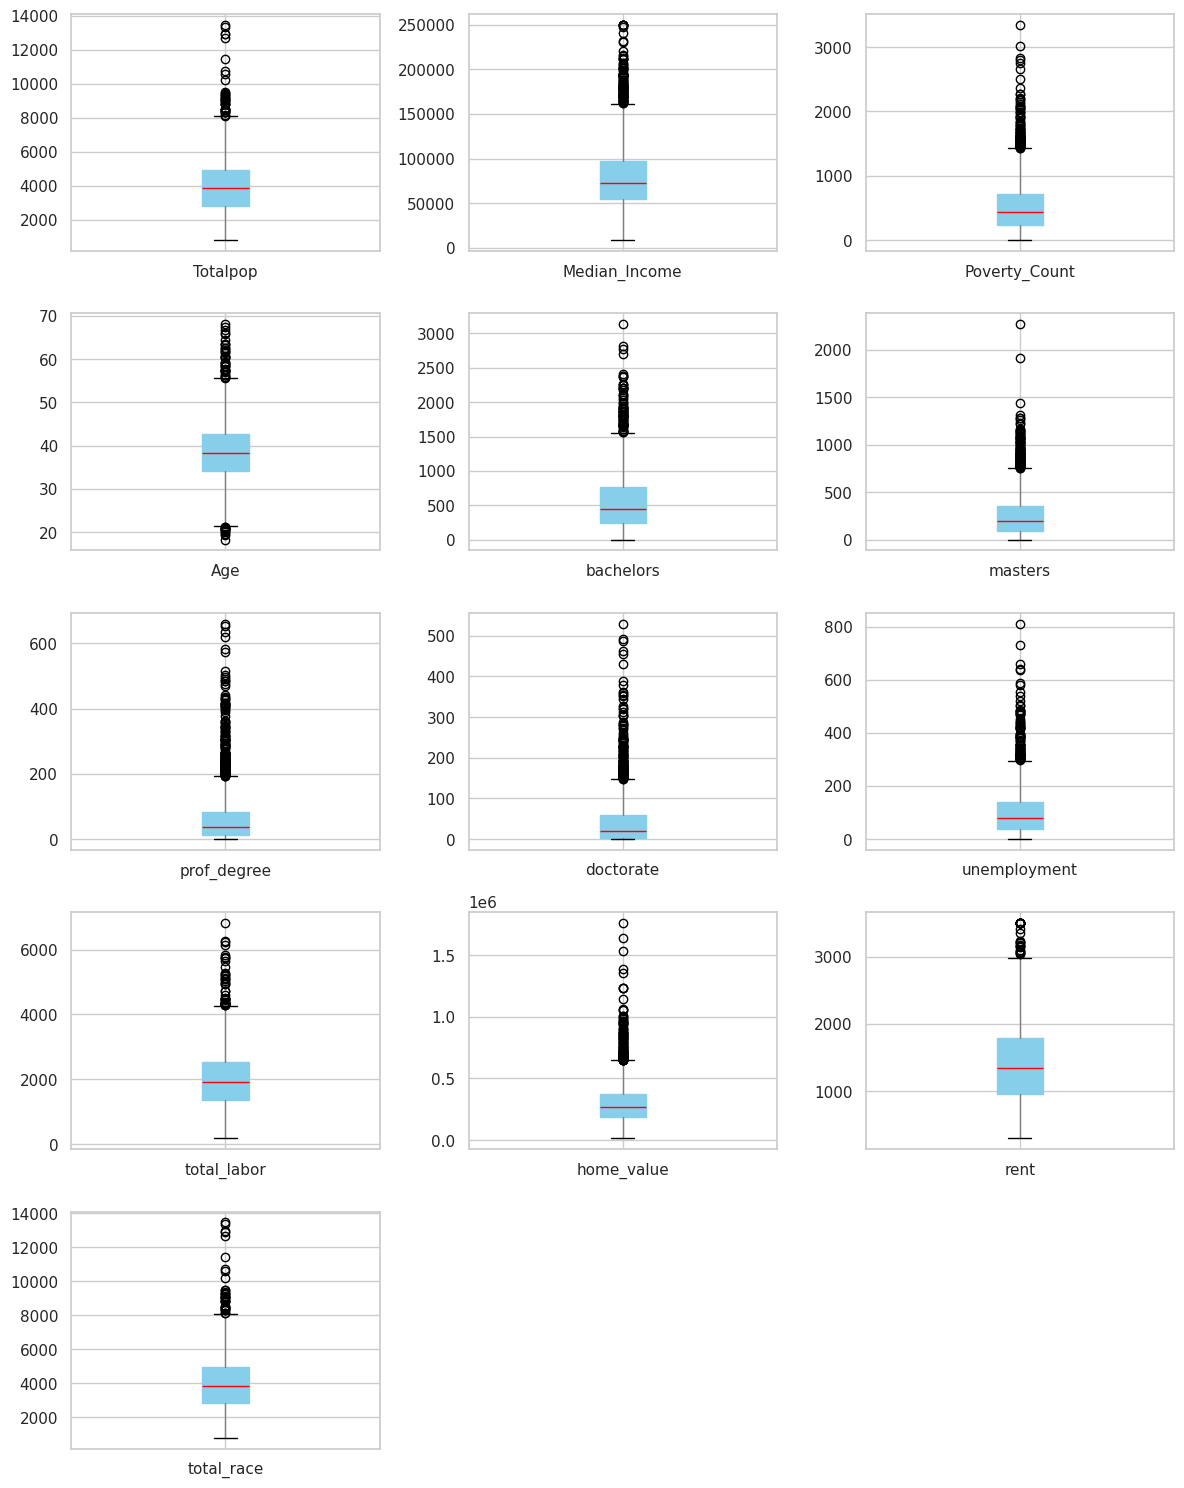

In [ ]:
# BOXPLOTS

df.plot(kind='box',
             subplots=True,
             layout=(5, 3),
             figsize=(12, 15),
             patch_artist=True,
             color=dict(boxes='skyblue', whiskers='gray', medians='red', caps='black'))

plt.tight_layout()
plt.show()

Totalpop Skewness: 0.92


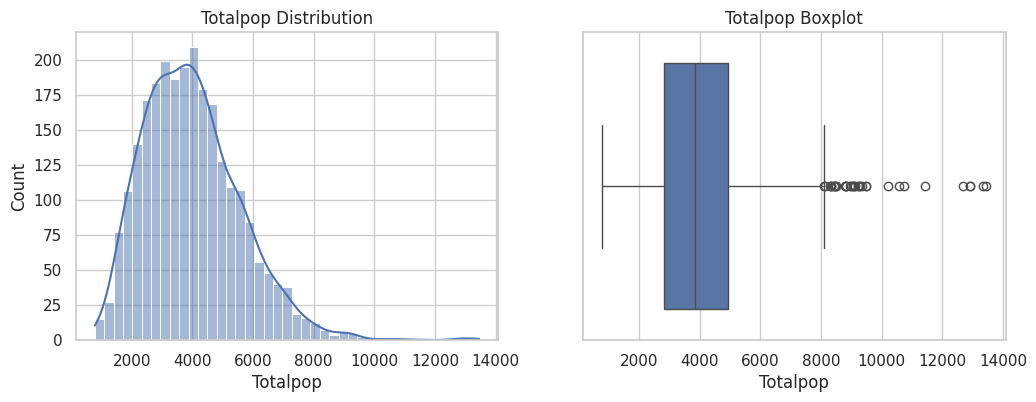

Median_Income Skewness: 1.25


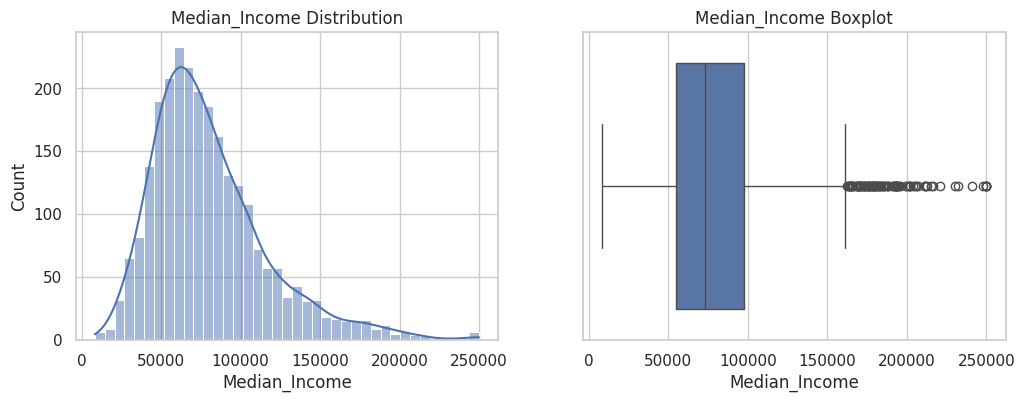

Poverty_Count Skewness: 1.60


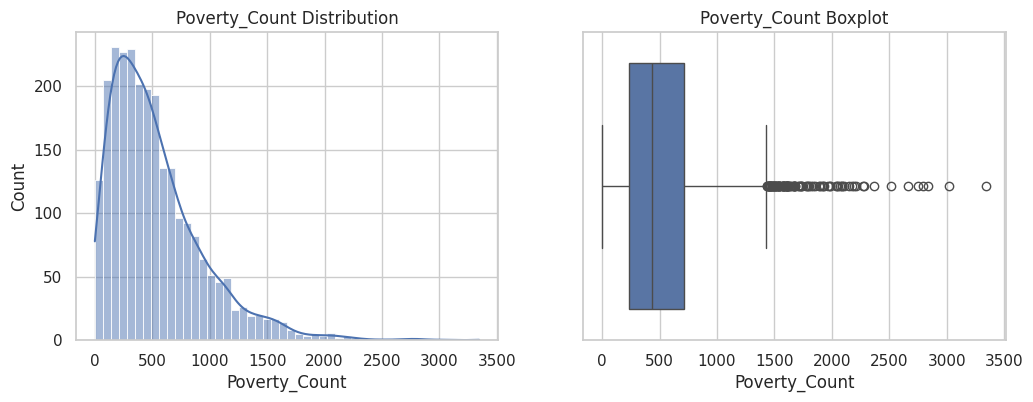

Age Skewness: 0.42


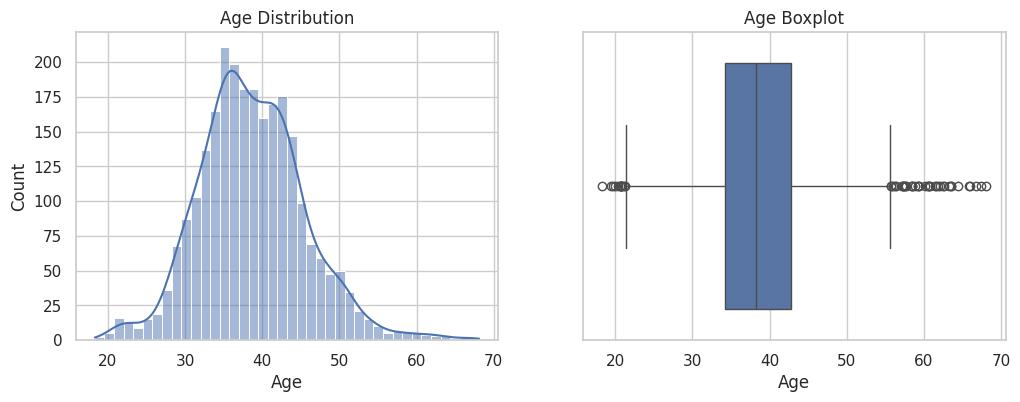

bachelors Skewness: 1.43


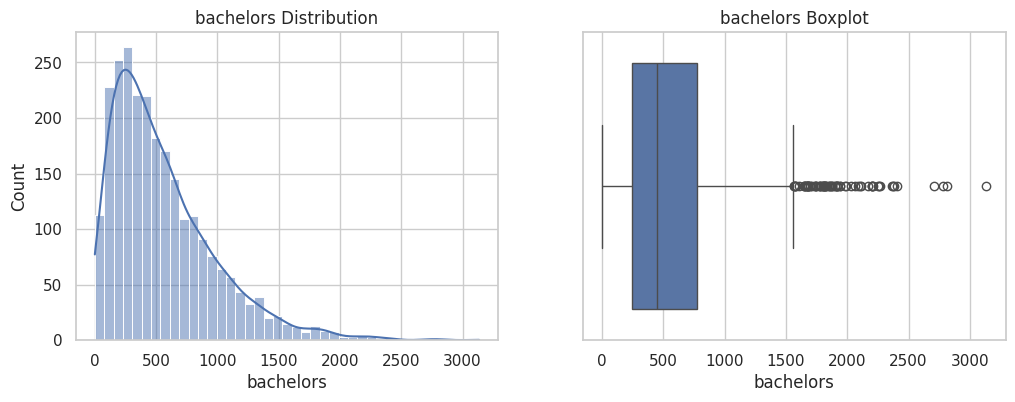

masters Skewness: 1.79


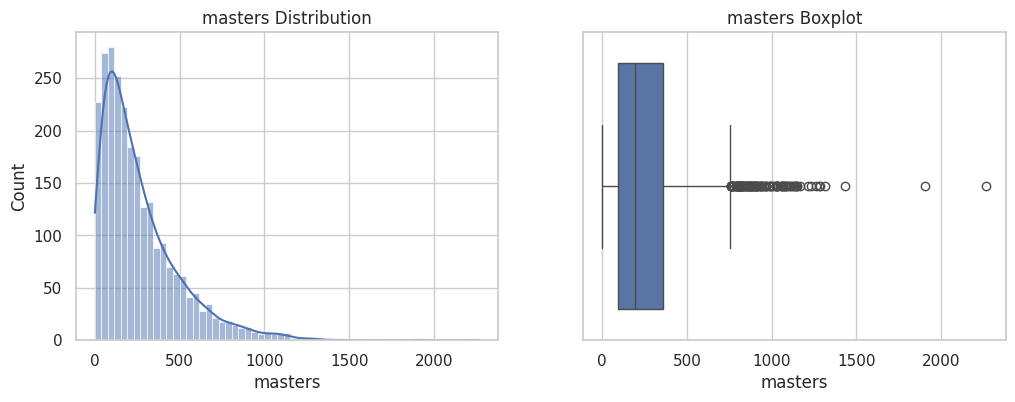

prof_degree Skewness: 2.70


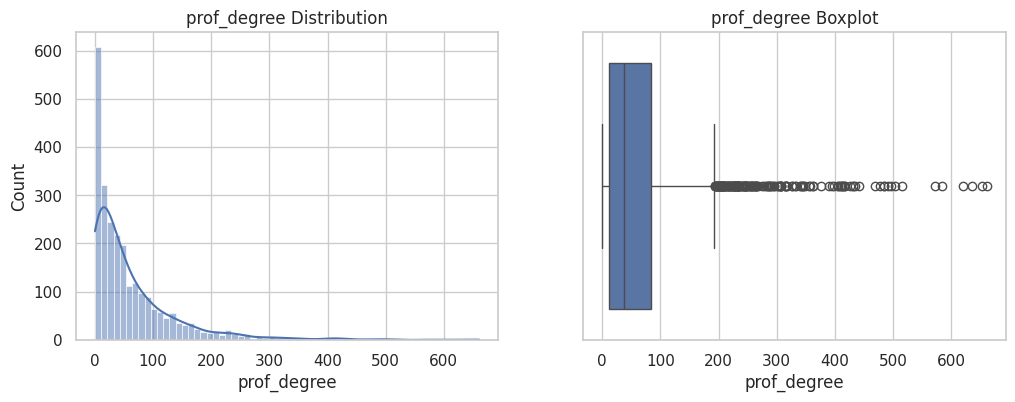

doctorate Skewness: 2.75


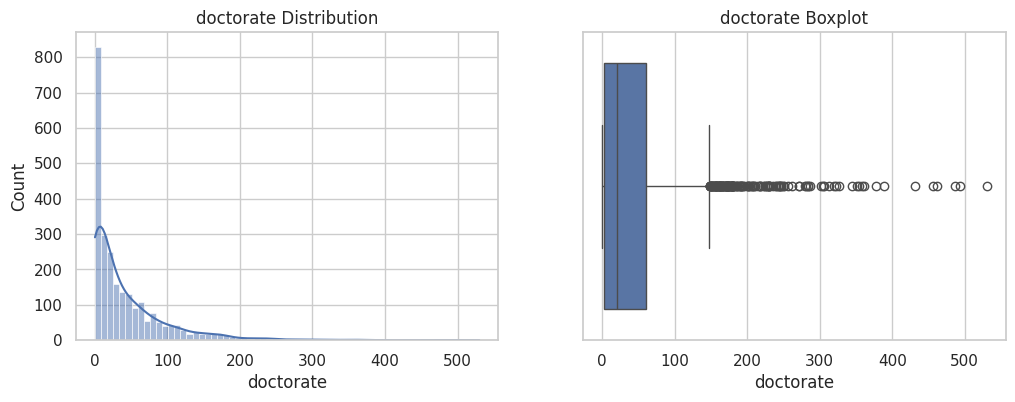

unemployment Skewness: 1.90


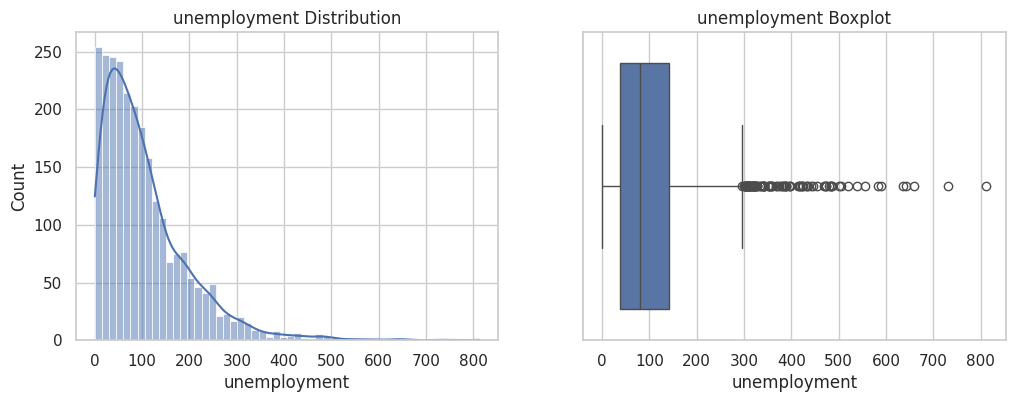

total_labor Skewness: 0.86


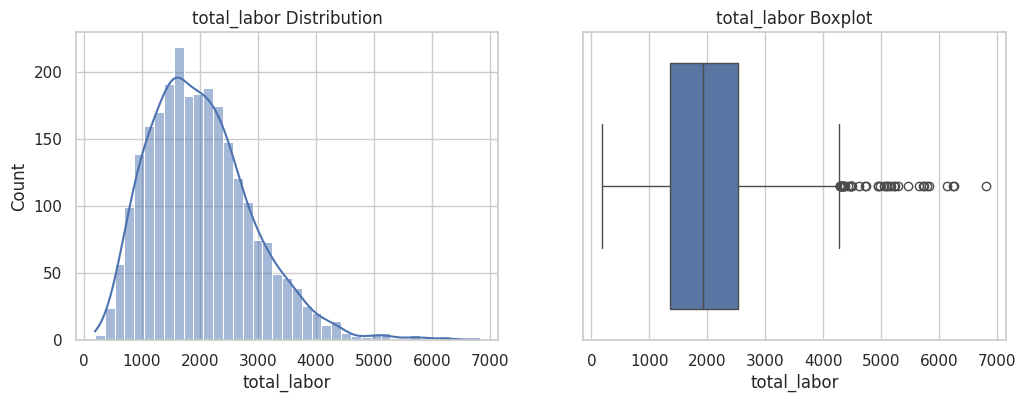

home_value Skewness: 1.87


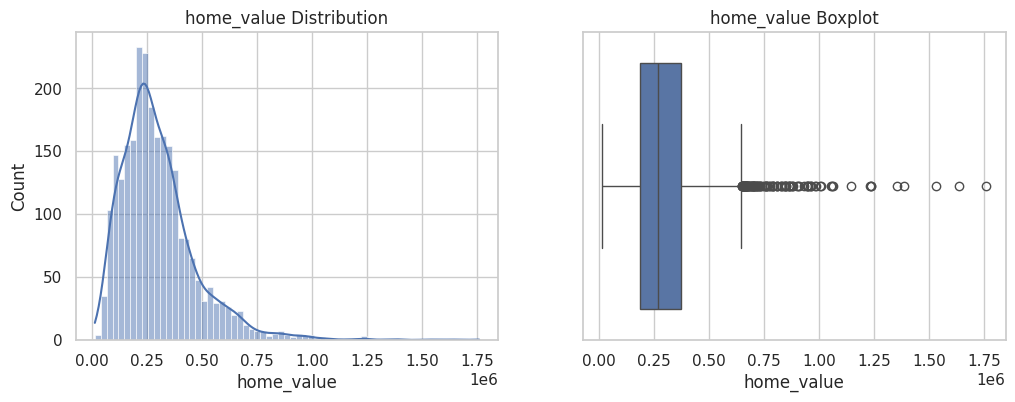

rent Skewness: 0.76


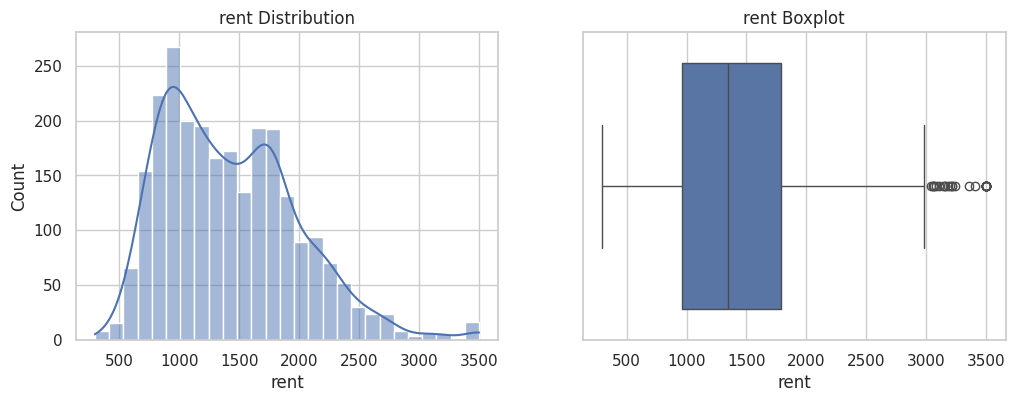

total_race Skewness: 0.92


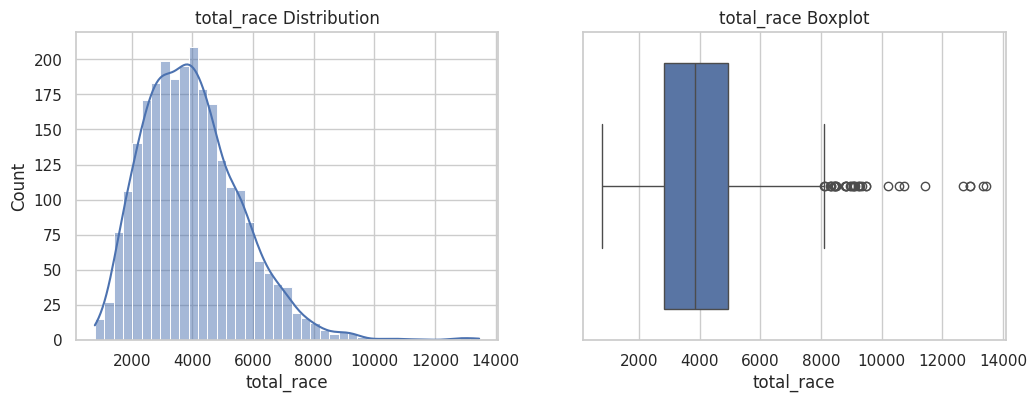

In [ ]:
#skewness plots
df_tiny = df[features].sample(n=min(100, len(df)))
for col in df_tiny:
    fig, axes = plt.subplots(1,2, figsize=(12,4))

    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f"{col} Distribution")

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"{col} Boxplot")

    print(f"{col} Skewness: {skew(df[col]):.2f}")
    plt.show()

SES INDEX

In [ ]:
# Turning some of our variables into rates instead
# (in case this helps for anything)

# Poverty rate
df["poverty_rate"] = df["Poverty_Count"] / df["Totalpop"]

# Education total
df["edu_total"] = (
    df["bachelors"] +
    df["masters"] +
    df["prof_degree"] +
    df["doctorate"]
)

# Education rate
df["edu_rate"] = df["edu_total"] / df["Totalpop"]

# Unemployment rate
df["unemployment_rate"] = df["unemployment"] / df["Totalpop"]


In [ ]:
# MAKING THE SES INDEX


# Standardization
features = df[[
    "Median_Income",
    "poverty_rate",
    "edu_rate",
    "unemployment_rate"
]]

scaler = StandardScaler()
scaled = scaler.fit_transform(features)

df_scaled = pd.DataFrame(scaled, columns=features.columns, index=df.index)

#Making the index itself
df["SES_index"] = (
    df_scaled["Median_Income"]
    - df_scaled["poverty_rate"]
    - df_scaled["unemployment_rate"]
    + df_scaled["edu_rate"]
)
# Factors that benefit SES are positive, factors that hurt SES are negative

In [ ]:
#SES Summary Stats

print(df["SES_index"].describe())

count    2.545000e+03
mean     6.030540e-16
std      2.971344e+00
min     -1.096091e+01
25%     -1.837901e+00
50%     -6.825679e-02
75%      1.762214e+00
max      9.770191e+00
Name: SES_index, dtype: float64


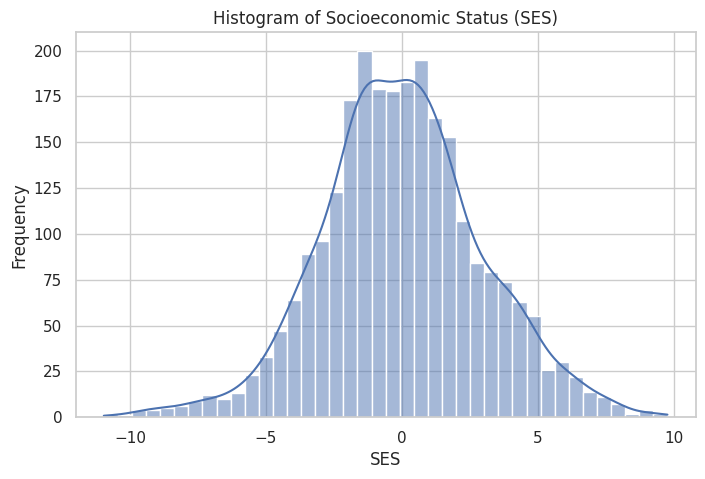

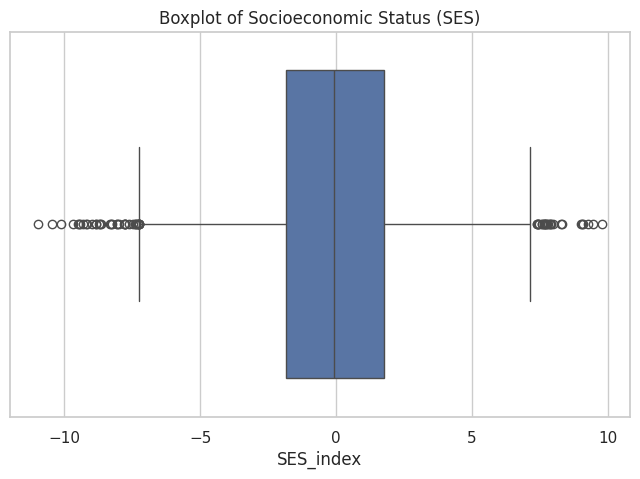

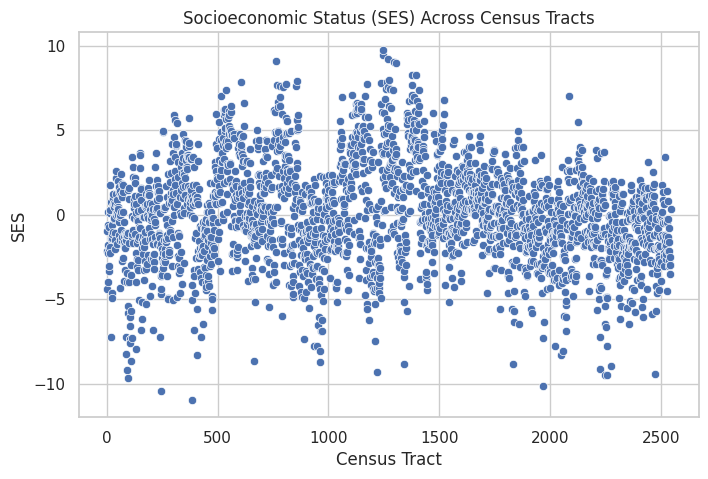

In [ ]:
# SES Hist.
sns.histplot(df["SES_index"], kde=True)

plt.title("Histogram of Socioeconomic Status (SES)")
plt.xlabel("SES")
plt.ylabel("Frequency")

plt.show()

# SES Boxplot
sns.boxplot(x=df["SES_index"])

plt.title("Boxplot of Socioeconomic Status (SES)")

plt.show()

# SES Scatter
sns.scatterplot(x=range(len(df)), y=df["SES_index"])

plt.title("Socioeconomic Status (SES) Across Census Tracts")
plt.xlabel("Census Tract")
plt.ylabel("SES")

plt.show()

In [ ]:
labels = ['Very Low SES','Low SES', 'Medium SES', 'High SES', 'Very High SES']


df['SES_bin'] = pd.cut(df['SES_index'],bins = 5, labels=labels)

print(df['SES_bin'].value_counts())

SES_bin
Medium SES       1394
High SES          641
Low SES           375
Very High SES      92
Very Low SES       43
Name: count, dtype: int64


BIVARIATE

In [ ]:
features = [
    "Totalpop", "Median_Income", "Poverty_Count", "poverty_rate","Age",
    "edu_total","edu_rate", "unemployment", "unemployment_rate", "total_labor",
    "home_value", "rent", "total_race"
]
target = "SES_bin"

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


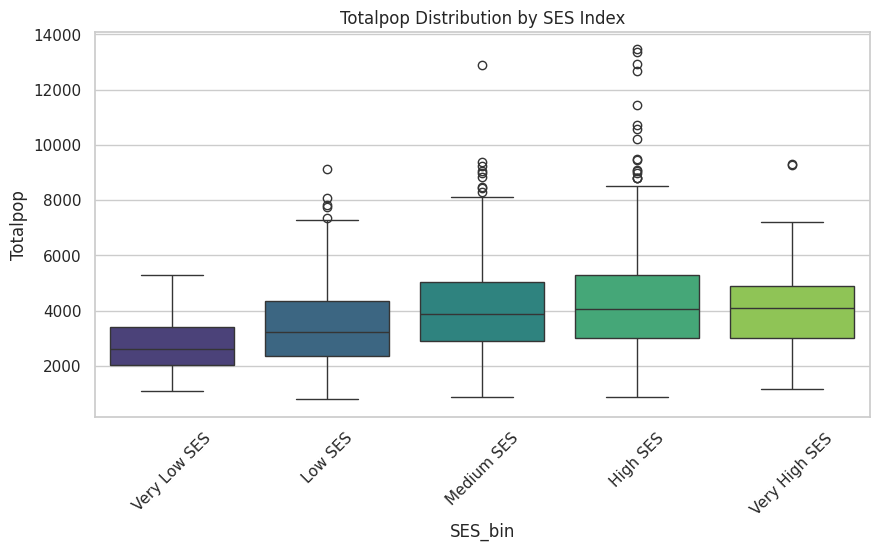

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


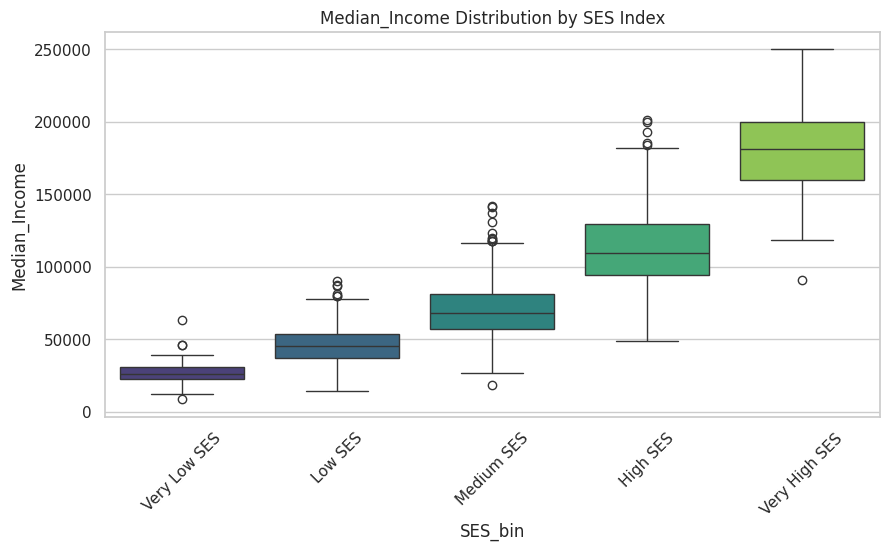

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


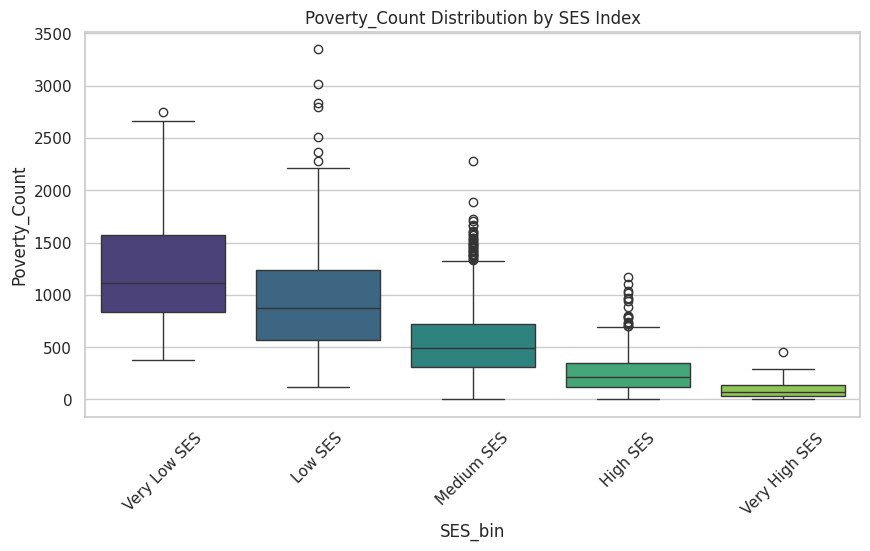

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


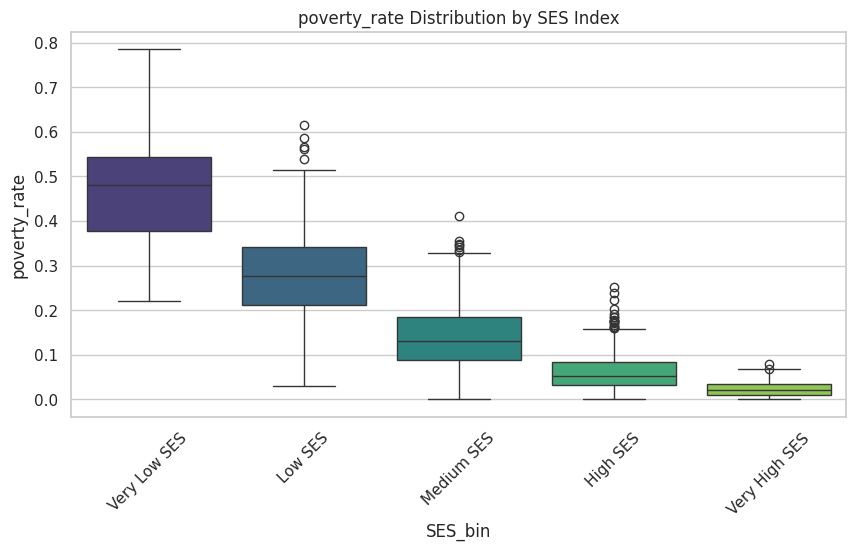

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


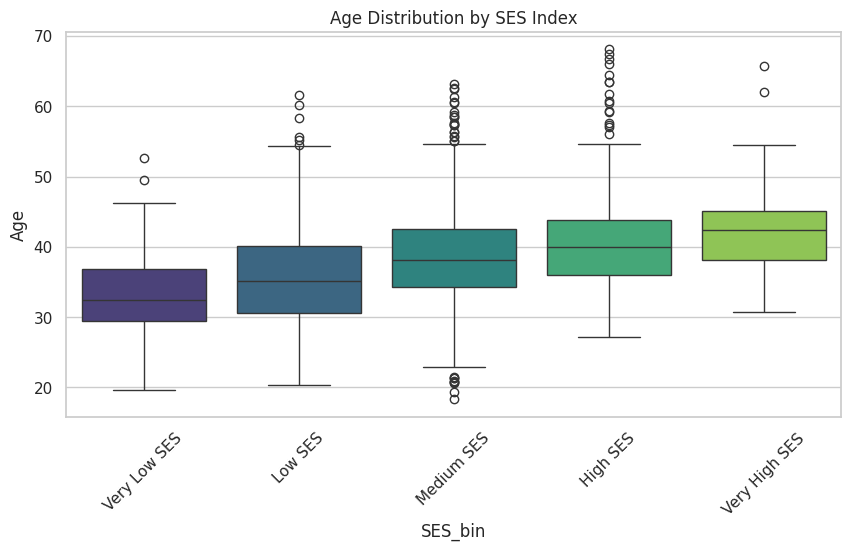

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


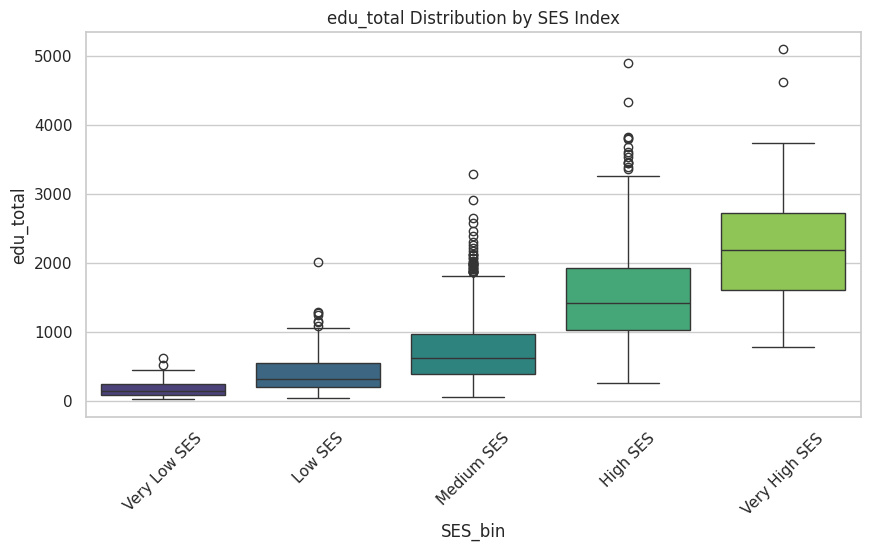

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


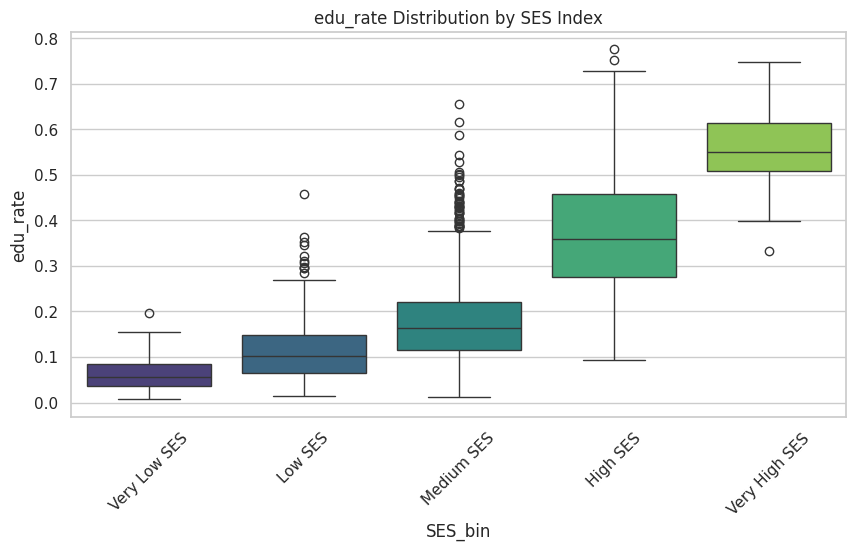

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


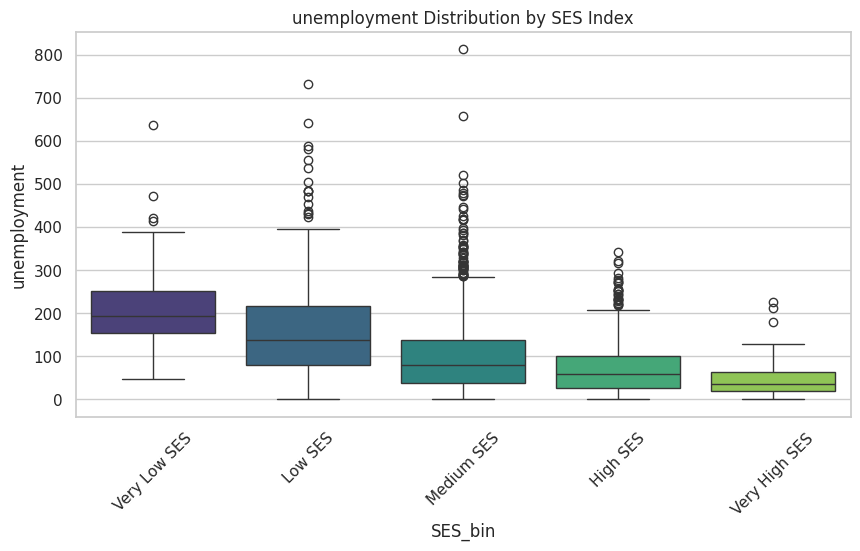

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


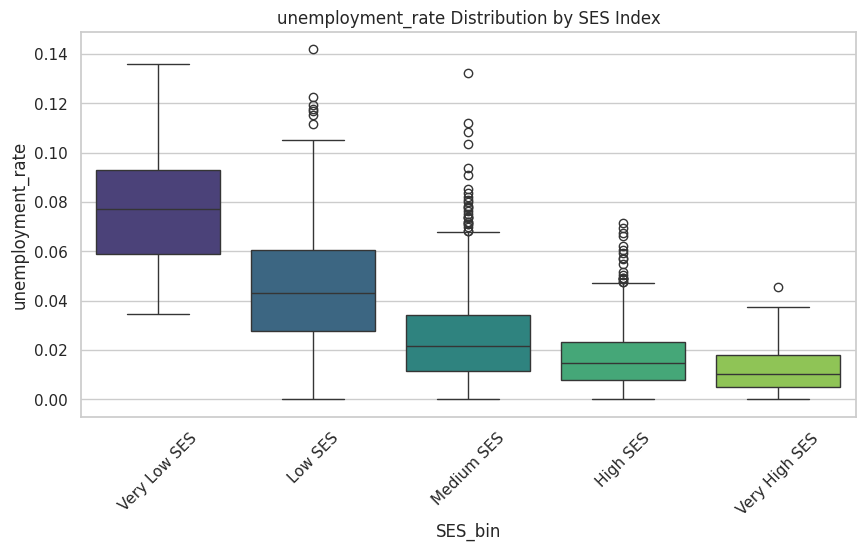

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


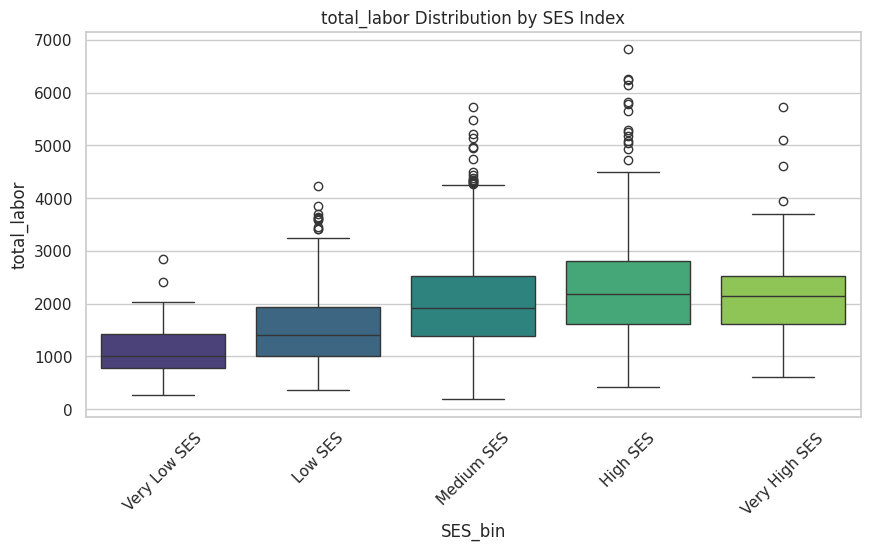

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


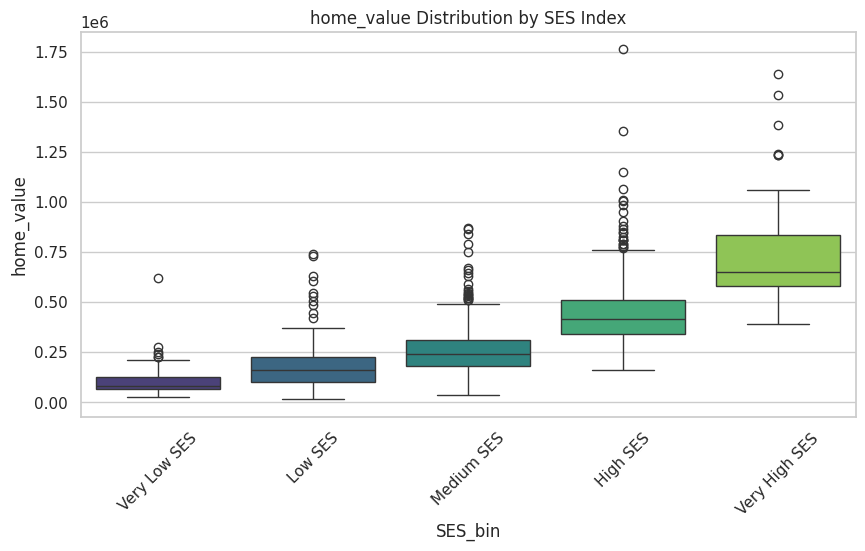

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


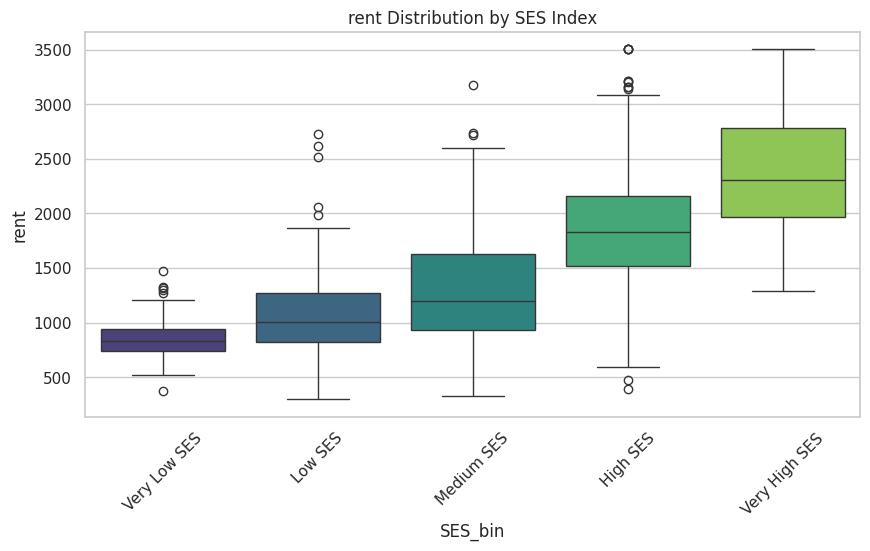

/tmp/ipykernel_17015/29980503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")


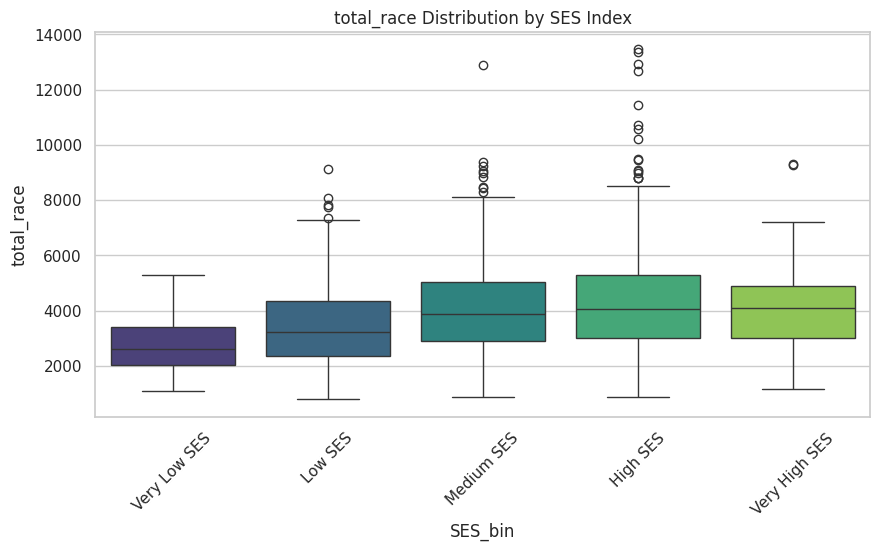

In [ ]:
#Ordering the SES bins
ses_order = ["Very Low SES", "Low SES", "Medium SES", "High SES", "Very High SES"]

for col in features:
    plt.figure(figsize=(10, 5))

    sns.boxplot(x="SES_bin", y=col, data=df, order=ses_order, palette="viridis")

    plt.title(f"{col} Distribution by SES Index")
    plt.xticks(rotation=45)

    plt.show()
    plt.close()

##Feature Transformation

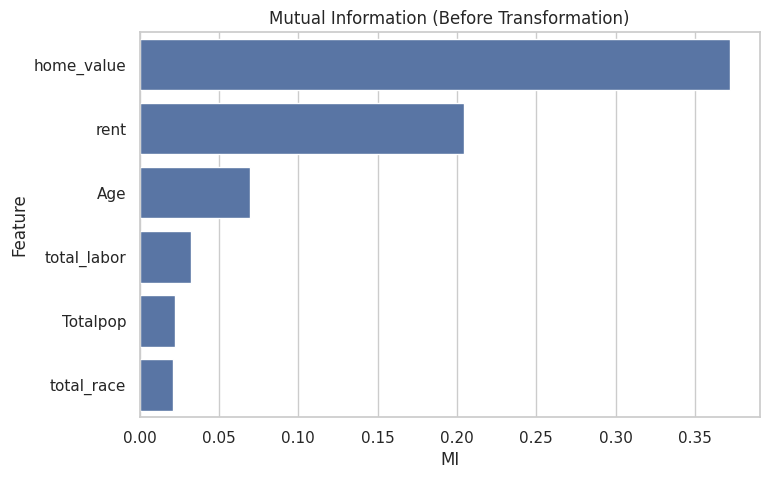

In [ ]:
features = [
    "Totalpop", "Age","total_labor",
    "home_value", "rent", "total_race"
]
#Mutual Information (Nonlinear importance)
X = df[features]
y = df[target].astype('category').cat.codes

mi = mutual_info_classif(X, y)

mi_df = pd.DataFrame({"Feature": features, "MI": mi})
mi_df.sort_values(by="MI", ascending=False, inplace=True)

sns.barplot(x="MI", y="Feature", data=mi_df)
plt.title("Mutual Information (Before Transformation)")
plt.show()

log transformation

In [ ]:
df_log = df.copy()

log_cols = ['home_value']

for col in log_cols:
    df_log[col] = np.log1p(df_log[col])

power transformation

In [ ]:
pt = PowerTransformer(method='yeo-johnson')

df_pt = df.copy()
df_pt[features] = pt.fit_transform(df_pt[features])


##BEFORE AFTER transformation

Skewness

In [ ]:
print("Before Transformation:")
for col in features:
    print(col, skew(df[col]))

print("\nAfter Log Transformation:")
for col in log_cols:
    print(col, skew(df_log[col]))


Before Transformation:
Totalpop 0.9234475961575114
Age 0.4154806371941951
total_labor 0.8617030736216788
home_value 1.873194298578745
rent 0.760158628472499
total_race 0.9234475961575114

After Log Transformation:
home_value -0.3599079757762347


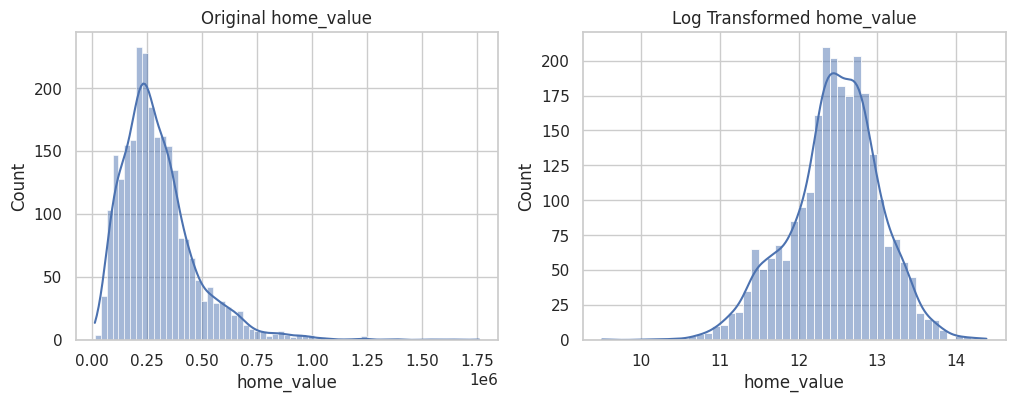

In [ ]:
for col in log_cols:
    fig, axes = plt.subplots(1,2, figsize=(12,4))

    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f"Original {col}")

    sns.histplot(df_log[col], kde=True, ax=axes[1])
    axes[1].set_title(f"Log Transformed {col}")

    plt.show()

Mutual Information Comparison

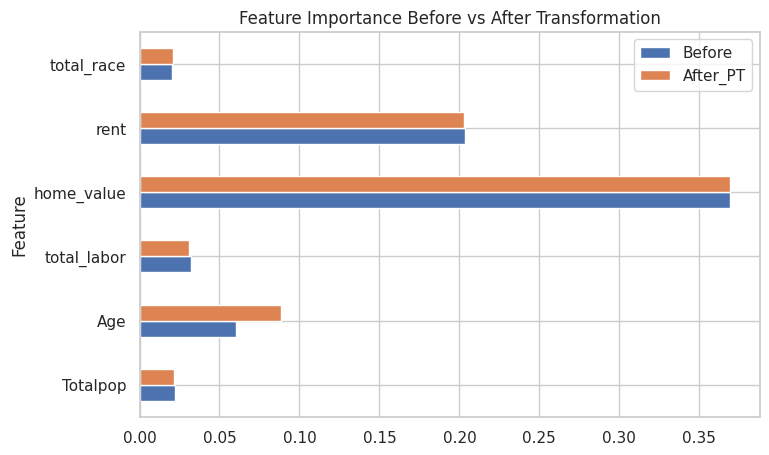

In [ ]:
# Before
mi_before = mutual_info_classif(df[features], y)

# After Power Transform
mi_after = mutual_info_classif(df_pt[features], y)

mi_compare = pd.DataFrame({
    "Feature": features,
    "Before": mi_before,
    "After_PT": mi_after
})

mi_compare.set_index("Feature").plot(kind="barh")
plt.title("Feature Importance Before vs After Transformation")
plt.show()


##Feature Engineering

/tmp/ipykernel_17015/52805131.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="MI", y="Feature", data=mi_df, palette="magma")


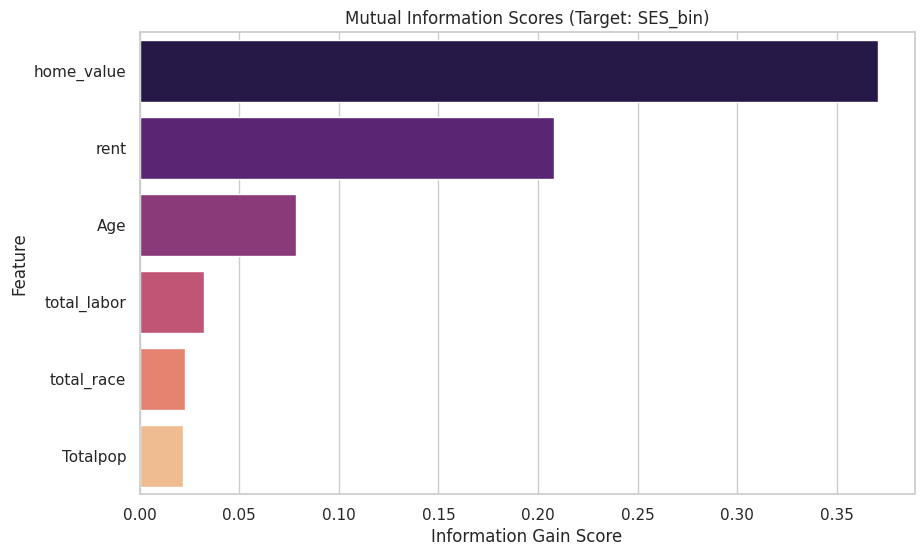

In [ ]:
# had to force them into a list
features_list = list(features)
all_cols = features_list + [target]


temp_df = df[all_cols].copy()
temp_df = temp_df.dropna().reset_index(drop=True)


X = temp_df[features_list]
y = temp_df[target].astype('category').cat.codes

mi = mutual_info_classif(X, y, random_state=36)

mi_df = pd.DataFrame({"Feature": features_list, "MI": mi})
mi_df.sort_values(by="MI", ascending=False, inplace=True)

plt.figure(figsize=(10, 6))
sns.barplot(x="MI", y="Feature", data=mi_df, palette="magma")
plt.title(f"Mutual Information Scores (Target: {target})")
plt.xlabel("Information Gain Score")
plt.show()

In [ ]:
pt = PowerTransformer(method='yeo-johnson')

df_pt = df.copy()
df_pt[features] = pt.fit_transform(df_pt[features])


HEATMAP

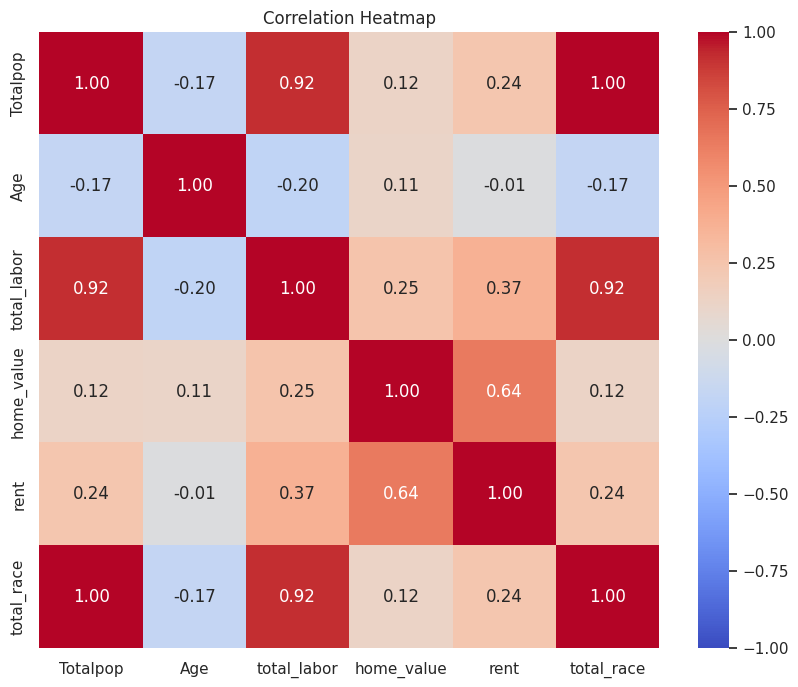

In [ ]:

plt.figure(figsize=(10, 8))


sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)

plt.title("Correlation Heatmap")
plt.show()

SCALING

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pt[features])

In [ ]:
# Step 1: Train (70%) + Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y, test_size=0.30, random_state=36, stratify=y
)

# Step 2: Validation (10%) + Test (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=36, stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1781, 6)
Validation: (254, 6)
Test: (510, 6)


UTILITY FUNCTION

In [ ]:
def evaluate_model(model, X_tr, y_tr, X_val, y_val):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    return acc


###HYPERPARAMETER TUNING

### Naive Bayes (GaussianNB)

In [ ]:
nb_results = []

for var_smoothing in [1e-9, 1e-8, 1e-7, 1e-6]:
    model = GaussianNB(var_smoothing=var_smoothing)
    acc = evaluate_model(model, X_train, y_train, X_val, y_val)
    nb_results.append((var_smoothing, acc))

best_nb = max(nb_results, key=lambda x: x[1])
print("Best NB:", best_nb)


Best NB: (1e-09, 0.5905511811023622)


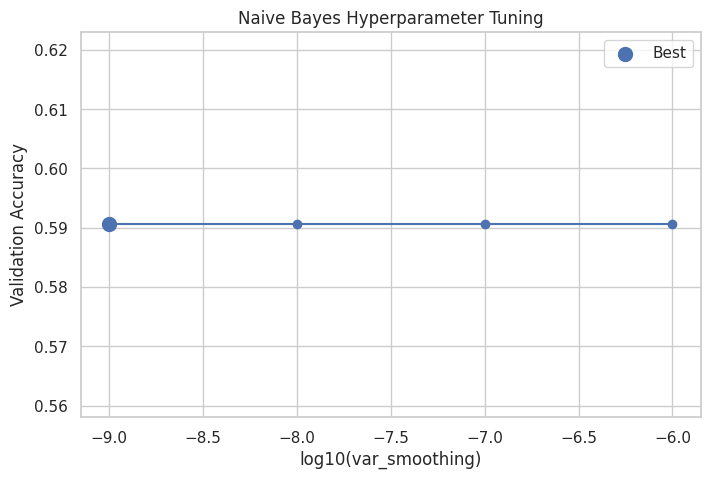

In [ ]:
# Convert results → DataFrame
nb_df = pd.DataFrame(nb_results, columns=["var_smoothing", "val_accuracy"])

# Sort by var_smoothing (important for line plot)
nb_df = nb_df.sort_values(by="var_smoothing")

# Convert to log scale for better visualization
nb_df["log_var_smoothing"] = np.log10(nb_df["var_smoothing"])

# -------------------------------
# Plot
# -------------------------------
plt.figure(figsize=(8,5))

plt.plot(
    nb_df["log_var_smoothing"],
    nb_df["val_accuracy"],
    marker="o",
    linestyle="-"
)

# Highlight best point
best_idx = nb_df["val_accuracy"].idxmax()

plt.scatter(
    nb_df.loc[best_idx, "log_var_smoothing"],
    nb_df.loc[best_idx, "val_accuracy"],
    s=100,
    label="Best",
)

plt.xlabel("log10(var_smoothing)")
plt.ylabel("Validation Accuracy")
plt.title("Naive Bayes Hyperparameter Tuning")
plt.grid(True)
plt.legend()

plt.show()

RANDOM FOREST

In [ ]:
rf_results = []

for n in [100, 200]:
    for depth in [5, 10, None]:
        for min_split in [2, 5]:
            model = RandomForestClassifier(
                n_estimators=n,
                max_depth=depth,
                min_samples_split=min_split,
                random_state=36,
                n_jobs=-1
            )
            acc = evaluate_model(model, X_train, y_train, X_val, y_val)
            rf_results.append((n, depth, min_split, acc))

best_rf = max(rf_results, key=lambda x: x[3])
print("Best RF:", best_rf)


Best RF: (100, 10, 5, 0.6732283464566929)


K-nearest neighbor

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

kn_results = []

for n in range(1, 100):
  knn=KNeighborsClassifier(n_neighbors=n, metric="euclidean")
  knn.fit(X_train, y_train)
  y_pred = knn.predict(X_test)
  acc = acc = accuracy_score(y_test, y_pred)
  kn_results.append((n, acc))

best_kn = max(kn_results,  key=lambda x: x[1])
print("Best RF:", best_kn)


Best RF: (21, 0.6901960784313725)


MLP (if)

In [ ]:
mlp_results = []

for hidden in [(64,), (128,), (64,64)]:
    for alpha in [0.0001, 0.001]:
        for lr in [0.001, 0.01]:
            model = MLPClassifier(
                hidden_layer_sizes=hidden,
                alpha=alpha,
                learning_rate_init=lr,
                max_iter=300,
                random_state=42
            )
            acc = evaluate_model(model, X_train, y_train, X_val, y_val)
            mlp_results.append((hidden, alpha, lr, acc))

best_mlp = max(mlp_results, key=lambda x: x[3])
print("Best MLP:", best_mlp)


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptro

Best MLP: ((128,), 0.0001, 0.01, 0.6811023622047244)


In [ ]:
# -------------------------------
# Convert results → DataFrame
# -------------------------------
mlp_df = pd.DataFrame(mlp_results, columns=[
    "hidden_layers", "alpha", "learning_rate", "val_accuracy"
])

# -------------------------------
# Encode hidden layers numerically
# -------------------------------
mlp_df["hidden_size"] = mlp_df["hidden_layers"].apply(lambda x: sum(x))
mlp_df["num_layers"] = mlp_df["hidden_layers"].apply(lambda x: len(x))

# -------------------------------
# Clean data
# -------------------------------
mlp_df = mlp_df.replace([np.inf, -np.inf], np.nan).dropna()

# -------------------------------
# Parallel Coordinates Plot
# (Validation Accuracy is LAST axis)
# -------------------------------
fig = px.parallel_coordinates(
    mlp_df,
    dimensions=[
        "hidden_size",
        "num_layers",
        "alpha",
        "learning_rate",
        "val_accuracy"   # <-- LAST COLUMN
    ],
    color="val_accuracy",
    color_continuous_scale=px.colors.sequential.Viridis,
    labels={
        "hidden_size": "Total Neurons",
        "num_layers": "Number of Layers",
        "alpha": "Regularization (alpha)",
        "learning_rate": "Learning Rate",
        "val_accuracy": "Validation Accuracy"
    },
    title="Parallel Coordinates Plot (MLP Hyperparameter Tuning)"
)

fig.show()

FINAL TRAIN

In [ ]:
# Combine train + validation
X_train_full = np.vstack([X_train, X_val])
y_train_full = np.concatenate([y_train, y_val])

Final Naives Bayes

In [ ]:
nb_final = GaussianNB(var_smoothing=best_nb[0])
nb_final.fit(X_train_full, y_train_full)

y_pred_nb = nb_final.predict(X_test)

FINAL RANDOM FOREST (MODEL 2)

In [ ]:
rf_final = RandomForestClassifier(
    n_estimators=best_rf[0],
    max_depth=best_rf[1],
    min_samples_split=best_rf[2],
    random_state=36,
    n_jobs=-1
)

rf_final.fit(X_train_full, y_train_full)
y_pred_rf = rf_final.predict(X_test)

K-Nearest Neighbor

In [ ]:
knn_final = KNeighborsClassifier(n_neighbors=best_kn[0], metric="euclidean")
knn_final.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)


### Final MLP

In [ ]:
mlp_final = MLPClassifier(
    hidden_layer_sizes=best_mlp[0],
    alpha=best_mlp[1],
    learning_rate_init=best_mlp[2],
    max_iter=300,
    random_state=42
)

mlp_final.fit(X_train_full, y_train_full)
y_pred_mlp = mlp_final.predict(X_test)

FINAL EVAL

In [ ]:
def print_results(name, y_true, y_pred):
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))
    print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))

print_results("Naive Bayes", y_test, y_pred_nb)
print_results("Random Forest", y_test, y_pred_rf)
print_results("K-Nearest Neighbor", y_test, y_pred_knn)
print_results("MLP", y_test, y_pred_mlp)


Naive Bayes
Accuracy: 0.6352941176470588

Classification Report:
               precision    recall  f1-score   support

           0       0.23      0.33      0.27         9
           1       0.38      0.35      0.36        75
           2       0.73      0.69      0.71       279
           3       0.60      0.73      0.66       128
           4       0.90      0.47      0.62        19

    accuracy                           0.64       510
   macro avg       0.57      0.51      0.53       510
weighted avg       0.64      0.64      0.64       510


Confusion Matrix:
 [[  3   5   1   0   0]
 [  8  26  38   3   0]
 [  2  36 193  48   0]
 [  0   1  33  93   1]
 [  0   0   0  10   9]]

Random Forest
Accuracy: 0.707843137254902

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       0.64      0.31      0.41        75
           2       0.72      0.90      0.80       279
           3       0.71

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

